# Text to image search on Flickr8k with CLIP

I embedded all Flickr8k images with pretrained CLIP (ViT-B/32) and return the top 5 images for a text query by cosine similarity. I also started a contrastive fine-tuning run but stopped it, so the retrieval shown here is zero-shot.

In [1]:
from transformers import CLIPModel, CLIPProcessor
import torch

# 1. Load the FULL multimodal model architecture
model_id = "openai/clip-vit-base-patch32"
model = CLIPModel.from_pretrained(model_id)
processor = CLIPProcessor.from_pretrained(model_id)

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

In [2]:
import datasets

ds = datasets.load_dataset("tsystems/flickr8k")
print(ds)

README.md:   0%|          | 0.00/492 [00:00<?, ?B/s]

data/train-00000-of-00003.parquet:   0%|          | 0.00/373M [00:00<?, ?B/s]

data/train-00001-of-00003.parquet:   0%|          | 0.00/364M [00:00<?, ?B/s]

data/train-00002-of-00003.parquet:   0%|          | 0.00/379M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/8091 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'image_filename', 'captions', 'query'],
        num_rows: 8091
    })
})


In [3]:
import matplotlib.pyplot as plt

def plot_tensor(tensor):
    # 1. Detach from graph, move to CPU, and convert to numpy
    img_array = tensor.detach().cpu().numpy()

    # 2. Check if it's a 3D image tensor (C, H, W)
    if len(img_array.shape) == 3:
        # Move channel from first dim to last dim: (C, H, W) -> (H, W, C)
        img_array = img_array.transpose(1, 2, 0)

    # 3. Plot it
    plt.imshow(img_array)
    plt.axis('off') # Hide grid axes
    plt.show()

In [28]:
import torch
from torchvision.transforms import v2
class LazyDataset(torch.utils.data.Dataset):
  def __init__(self, dataset):
    self.dataset = ds['train']

    virtual_pairs = []
    for img_idx in range(len(self.dataset)):
        num_captions = len(self.dataset['captions'][img_idx])
        for cap_idx in range(num_captions-4):
            virtual_pairs.append((img_idx, cap_idx))

    self.pairs = virtual_pairs
    self.to_tensor = v2.Compose([
        v2.ToTensor(),
        v2.Resize((224, 224))
    ])

  def __len__(self):
    return len(self.pairs)

  def __getitem__(self, idx):
    pair = self.pairs[idx]
    image = self.dataset['image'][pair[0]]
    caption = self.dataset['captions'][pair[0]][pair[1]]

    return (image, caption, pair[0], pair[1])

In [29]:
data = LazyDataset(ds)

/usr/local/lib/python3.12/dist-packages/torchvision/transforms/v2/_deprecated.py:42: UserWarning: The transform `ToTensor()` is deprecated and will be removed in a future release. Instead, please use `v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])`.Output is equivalent up to float precision.
  warnings.warn(


In [6]:
print(processor.tokenizer.model_max_length)

77


In [30]:
def cust_collator(batch):
  imgs = [sample[0] for sample in batch]
  texts = [sample[1] for sample in batch]
  pair_0 = [sample[2] for sample in batch]
  pair_1 = [sample[3] for sample in batch]

  if isinstance(texts[0], list):
    texts = [item for sublist in texts for item in sublist]

  ## tokenizer

  inputs = processor(
    text=texts,
    images=imgs,
    return_tensors="pt",
    padding = True, # padding = 'max_length' means CLIP's max length so 77 tokens
    truncation = True
  )

  inputs['pair_0'] = pair_0
  inputs['pair_1'] = pair_1

  return inputs

In [33]:
from torch.utils.data import DataLoader

loader_train = DataLoader(data, batch_size = 32, shuffle = True, collate_fn = cust_collator)

In [ ]:
#input_ids, attention_mask, pixel_values

In [ ]:
from tqdm import tqdm
import numpy as np
def compute_accuracy(logits, labels):
    """
    Computes top-1 accuracy given logits and ground truth labels.
    """
    model.eval()
    # Get the index of the max logit along the prediction dimension
    preds = torch.argmax(logits, dim=-1)

    # Compare predictions to true labels and calculate the mean
    correct = (preds == labels).float()
    acc = correct.mean() * 100 # Returns percentage (0-100)

    return acc.item()

def train_CLIP(model, processor, epochs, optimizer, criterion):
  total_loss = 0
  model.train()
  for epoch in tqdm(range(epochs)):
    local_loss = 0
    total = 0
    for idx, datas in enumerate(loader_train):
      optimizer.zero_grad()
      outputs = model(**datas)

      logits_imgs = outputs['logits_per_image']
      logits_texts = outputs['logits_per_text']

      labels = torch.arange(logits_texts.shape[0], dtype=torch.long, device=logits_texts.device)

      loss_imgs = criterion(logits_imgs, labels)
      loss_texts = criterion(logits_texts, labels)

      loss = (loss_imgs + loss_texts)/2

      loss.backward()

      optimizer.step()

      print(f"Epoch {epoch}: Loss, {loss}")
      print(f"Img_acc: {compute_accuracy(logits_imgs, labels)}, Text_acc: {compute_accuracy(logits_texts, labels)}")



In [ ]:
import torch
import torch.nn as nn

# Instantiate the optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=8e-7, weight_decay=0.02)
criterion = nn.CrossEntropyLoss()

train_CLIP(model, processor, 2, optimizer, criterion)

  0%|          | 0/2 [00:15<?, ?it/s]


In [43]:
import torch
from tqdm import tqdm

def getty(loader_train):
    device = 'cuda' if torch.cuda.is_available() else 'cpu'

    model.to(device)
    model.eval()

    img_list = []
    text_list = []
    index_list = []

    for idx, batch in enumerate(tqdm(loader_train, desc="Extracting CLIP Embeddings", unit="batch")):
        pixel_values = batch['pixel_values'].to(device)
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)

        # 'pair_0' is likely a list (e.g., strings or un-collated ints)
        batch_idx = batch['pair_0']

        with torch.no_grad():
            # 1. Extract features
            img_outputs = model.visual_projection(model.vision_model(pixel_values=pixel_values).pooler_output)
            txt_outputs = model.text_projection(model.text_model(input_ids=input_ids, attention_mask=attention_mask).pooler_output)

            # 3. Apply unit L2 normalization
            img_feats = torch.nn.functional.normalize(img_outputs, p=2, dim=-1)
            txt_feats = torch.nn.functional.normalize(txt_outputs, p=2, dim=-1)

            # Push vectors back to CPU memory
            img_list.append(img_feats.cpu())
            text_list.append(txt_feats.cpu())

            # --- FIX HERE ---
            # If it's already a tensor, just move it to CPU. Otherwise, keep it as a list/extend.
            if isinstance(batch_idx, torch.Tensor):
                index_list.append(batch_idx.cpu())
            else:
                index_list.extend(batch_idx) # Flattening the batch lists into one big list

    images = torch.cat(img_list, dim=0)
    texts = torch.cat(text_list, dim=0)

    # --- FIX HERE ---
    if all(isinstance(x, torch.Tensor) for x in index_list):
        index = torch.cat(index_list, dim=0)
    else:
        # If they are strings or standard Python types, return a regular list or numpy array
        index = index_list

    return (images, texts, index)

In [44]:
model.to('cuda')
images, texts, indexes = getty(loader_train)

Extracting CLIP Embeddings: 100%|██████████| 253/253 [01:37<00:00,  2.60batch/s]


In [61]:
import torch
import matplotlib.pyplot as plt
import seaborn as sns

def compare_and_plot_topk(image_embeddings, text_embeddings, indexes, text_labels=None, top_k=3):


    similarity_matrix = torch.matmul(text_embeddings, image_embeddings.T).to('cuda')

    num_texts, num_images = similarity_matrix.shape
    if text_labels is None:
        text_labels = [f"Text Query {i}" for i in range(num_texts)]

    print(f"--- Top {top_k} Image Matches Per Text Query ---")

    # 2. Retrieve Top-K indices and values across the image dimension
    top_k_values, top_k_indices = torch.topk(similarity_matrix, k=min(top_k, num_images), dim=1)

    for i, label in enumerate(text_labels):
        print(f"\nQuery: '{label}'")
        for rank in range(len(top_k_indices[i])):
            img_idx = top_k_indices[i][rank].item()
            score = top_k_values[i][rank].item()
            print(f"  -> Rank {rank+1}: Image Index {indexes[img_idx]} (Similarity: {score:.4f})")
            display(ds['train']['image'][indexes[img_idx]])

    # 3. Plotting the Alignment Heatmap
    #plt.figure(figsize=(max(8, num_images * 0.8), max(6, num_texts * 0.6)))

    # Convert matrix to numpy for seaborn plotting



--- Top 5 Image Matches Per Text Query ---

Query: 'Text Query 0'
  -> Rank 1: Image Index 3162 (Similarity: 0.2629)


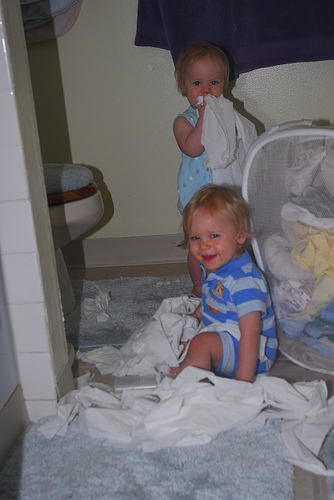

  -> Rank 2: Image Index 3357 (Similarity: 0.2586)


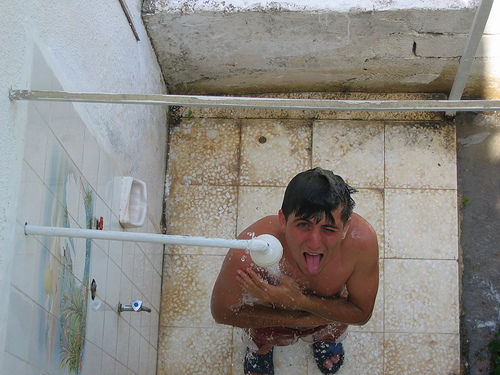

  -> Rank 3: Image Index 2009 (Similarity: 0.2487)


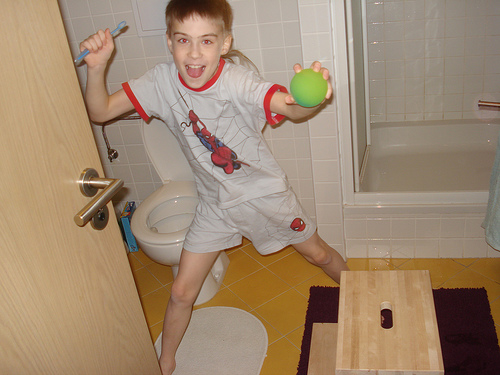

  -> Rank 4: Image Index 1826 (Similarity: 0.2429)


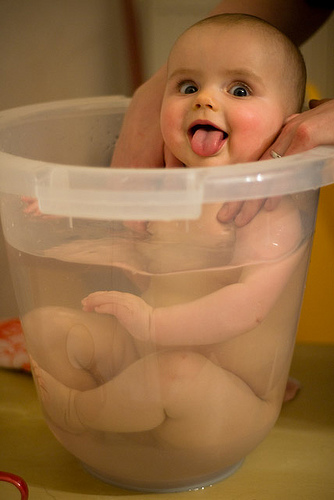

  -> Rank 5: Image Index 5986 (Similarity: 0.2367)


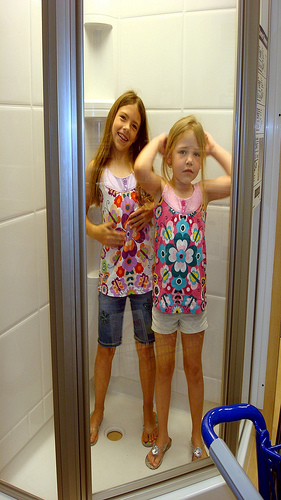

In [83]:
inputs = processor(text=['Dirty Toilet'], return_tensors="pt")

# 3. Move all input tensors to the same device as the model
inputs = {k: v.to('cuda') for k, v in inputs.items()}

# 4. Pass them into the text model
with torch.no_grad():
    embs = model.text_projection(model.text_model(**inputs).pooler_output)
    embs = torch.nn.functional.normalize(embs, p=2, dim=-1)

#print(torch.tensor(indexes, dtype=torch.long))
indexes_tensor = torch.tensor(indexes, dtype=torch.long).flatten().to('cuda')

compare_and_plot_topk(
    image_embeddings = images.to('cuda'),
    text_embeddings = embs.to('cuda'),
    indexes = indexes,
    top_k=5)

In [ ]:
with torch.no_grad():
  print(inputs)


tensor([[-0.6839, -0.0124, -0.0562,  ...,  0.7303,  0.2724,  0.1700],
        [-0.1018, -0.0503, -0.0660,  ...,  0.5587, -0.2745,  0.2239],
        [-0.0020, -0.0036,  0.3264,  ...,  0.7686,  0.1976, -0.0467],
        ...,
        [-0.1233,  0.2139, -0.0577,  ...,  0.6333,  0.2013, -0.0019],
        [ 0.0752, -0.0941,  0.0293,  ...,  0.4134,  0.2644, -0.0142],
        [-0.0948,  0.3735, -0.0475,  ...,  0.5212, -0.4759, -0.0564]],
       device='cuda:0')
